# Performing DEG Pathway analysis (limma, R) on Pseudobulked DC1, DC2s and mreg DCs from atlas
* Ovarian cancer samples only
* dataframes made previously (2026-04-10_PseudobulkingSampleType_fromNRcode.jpynb), separate for each DC subset and each has seperate metadata file
* Following code from NR 2025-02-12_Pseudo_Cancer_DEGS.
* Looking at primary vs mets only

Flipping the primary vs metastatic tumour comparison so that changes in the primary are positive here.
Code modified from 2026-06-08_OC_Pseudo_DEG_pathways_DC1PrimaryvOthers.ipynb
Code modified from 2026-06-08_OC_Pseudo_DEG_pathways_DC2PrimaryvOthers.ipynb
Code modified from 2026-04-24_OC_Pseudo_DEG_pathways_mregDCPrimaryvOthersv2.ipynb

In [1]:
library(limma)
library(edgeR)
library(dplyr)
library(RColorBrewer)
library(ggplot2)
library(pheatmap)
library(ggrepel)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:

# set directory
setwd('/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/Pseudobulk')

## Load data - DC1

In [3]:
list.files()

[1] "dc1_limma_DEG.csv"                           
 [2] "dc2_limma_DEG.csv"                           
 [3] "MetastaticComps"                             
 [4] "mregdc_limma_DEG.csv"                        
 [5] "MTvPT_DEG_results"                           
 [6] "OC_DC1"                                      
 [7] "OC_DC2"                                      
 [8] "OC_mregDC"                                   
 [9] "oc_pseudobulk_DC1_data.csv"                  
[10] "oc_pseudobulk_DC2_data.csv"                  
[11] "oc_pseudobulk_mregDC_data.csv"               
[12] "oc_pseudobulk_sampletype_metadata_DC1.csv"   
[13] "oc_pseudobulk_sampletype_metadata_DC2.csv"   
[14] "oc_pseudobulk_sampletype_metadata_mregDC.csv"
[15] "pseudobulk_DC1_data.csv"                     
[16] "pseudobulk_DC2_data.csv"                     
[17] "pseudobulk_metadata_DC1.csv"                 
[18] "pseudobulk_metadata_DC2.csv"                 
[19] "pseudobulk_metadata_mregDC.csv"              
[20] "pseudobulk_mregDC_data.csv"                  
[21] "pseudobulk_sampletype_metadata_DC1.csv"      
[22] "pseudobulk_sampletype_metadata_DC2.csv"      
[23] "pseudobulk_sampletype_metadata_mregDC.csv"   
[24] "PT-MT_limma_dc1.csv"                         
[25] "PT-MT_limma_dc2.csv"                         
[26] "PT-MT_limma_mregDC.csv"

In [4]:
#load data
sampleinfo <- read.csv("oc_pseudobulk_sampletype_metadata_DC1.csv", row.names =1)
head(sampleinfo)

,sample_type_major2
,<chr>
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_RIGHT_ADNEXA,primary tumour


In [5]:
dim(sampleinfo)

[1] 170   1

In [6]:
cts_DC1 <- read.csv("oc_pseudobulk_DC1_data.csv")
head(cts_DC1)

,X,GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM,⋯,PRJCA005422_HGSOC4_PT,PRJCA005422_HGSOC5_AS,PRJCA005422_HGSOC6_AS,PRJCA005422_HGSOC6_MT,PRJCA005422_HGSOC7_PT,PRJCA005422_HGSOC8_AS,PRJCA005422_HGSOC8_PT,PRJCA005422_HGSOC9_AS,PRJCA005422_HGSOC9_PT,PRJCA005422_HGSOC10_AS
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FAM87B,0,0,0,0,0,1,0,0,1,⋯,0,0,0,0,0,0,0,0,0,0
2,LINC00115,0,0,0,0,0,0,0,0,0,⋯,1,0,0,0,0,2,0,5,0,1
3,FAM41C,0,0,0,1,0,0,0,0,0,⋯,0,1,0,0,0,0,0,0,0,0
4,SAMD11,0,1,0,0,0,0,0,0,0,⋯,0,0,0,0,1,0,0,0,0,0
5,NOC2L,5,4,1,1,3,0,2,3,0,⋯,3,21,2,1,2,9,4,28,1,16
6,KLHL17,0,0,0,0,0,0,0,0,0,⋯,0,1,0,0,0,1,0,0,0,1


In [7]:
dim(cts_DC1)

[1] 15074   171

In [8]:
# set genes variables
genes <- data.frame(Symbol = row.names(cts_DC1))

In [9]:
# create DGEList variable
y <- DGEList(counts = cts_DC1, genes = genes)

Setting first column of `counts` as gene annotation.



In [10]:
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
1                                              0
2                                              0
3                                              0
4                                              0
5                                              5
6                                              0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
1                                                        0
2                                                        0
3                                                        0
4                                                        1
5                                                        4
6                                                        0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
1                                                 0
2                                                 0
3                                                 0
4                                                 0
5                                                 1
6                                                 0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
1                                                         0
2                                                         0
3                                                         1
4                                                         0
5                                                         1
6                                                         0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
1                                                       0
2                                                       0
3                                                       0
4                                                       0
5                                                       3
6                                                       0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
1                                                  1
2                                                  0
3                                                  0
4                                                  0
5                                                  0
6                                                  0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
1                                                          0
2                                                          0
3                                                          0
4                                                          0
5                                                          2
6                                                          0
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
1                                        0
2                                        0
3                                        0
4                                        0
5                                        3
6                                        0
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
1                                                     1
2                                                     0
3                                                     0
4                                                     0
5                                                     0
6                                                     0
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
1                                        0
2                                        2
3                                        1
4                                        0
5                                        7
6                                        1
  GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM
1                                                     0
2                                                     1
3                                                     0
4

In [11]:
dim(y)

[1] 15074   170

### Filtering:

In [12]:
# Keep genes with total counts more than 50.
A <- rowSums(y$counts)
isexpr <- A > 50

In [13]:
# Keep only genes with defined annotation:
hasannot <- rowSums(is.na(y$genes)) == 0

In [14]:
y <- y[isexpr & hasannot, , keep.lib.size = FALSE]
dim(y)

[1] 9997  170

### Normalise data

In [15]:
y <- calcNormFactors(y)
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
2                                              0
5                                              5
6                                              0
7                                              0
8                                              0
9                                              8
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
2                                                        0
5                                                        4
6                                                        0
7                                                        0
8                                                        0
9                                                      184
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
2                                                 0
5                                                 1
6                                                 0
7                                                 0
8                                                 1
9                                                40
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
2                                                         0
5                                                         1
6                                                         0
7                                                         0
8                                                         0
9                                                        18
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
2                                                       0
5                                                       3
6                                                       0
7                                                       0
8                                                       1
9                                                     139
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
2                                                  0
5                                                  0
6                                                  0
7                                                  0
8                                                  0
9                                                  6
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
2                                                          0
5                                                          2
6                                                          0
7                                                          1
8                                                          0
9                                                          7
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
2                                        0
5                                        3
6                                        0
7                                        0
8                                        6
9                                      118
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     0
5                                                     0
6                                                     0
7                                                     0
8                                                     0
9                                                     4
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
2                                        2
5                                        7
6                                        1
7                                        2
8                                        6
9                                      972
  GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     1
5                                                     4
6                                                     0
7

## Set Up Model

In [16]:
# setup model
design <- model.matrix(~ 0 + sample_type_major2, data = sampleinfo)

In [17]:
colnames(design) <- c("primary tumour","metastatic tumour","ascites","healthy")

In [18]:
head(design)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_RIGHT_ADNEXA,0,0,0,1


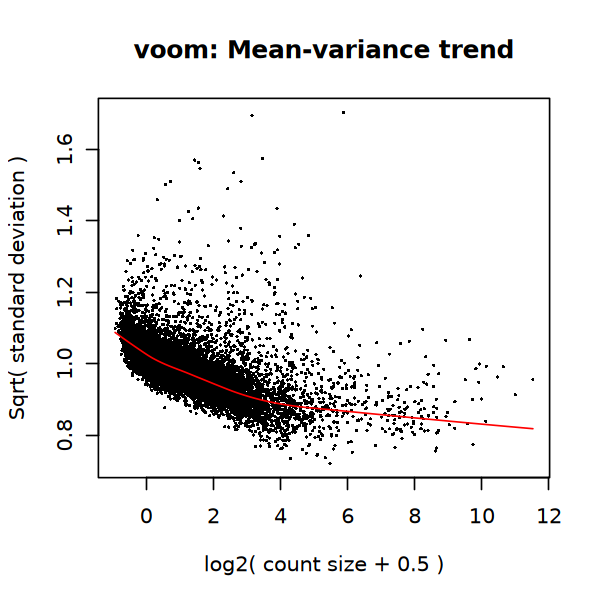

In [19]:
#voom - see here for good v bad voom plot: https://ucdavis-bioinformatics-training.github.io/2018-June-RNA-Seq-Workshop/thursday/DE.html
options(repr.plot.height=5, repr.plot.width=5)
v <- voom(y, design, plot = TRUE)

In [20]:
# lmFit
fit <- lmFit(v, design)

### Primary vs Metastatic set as design 1 and 2

In [21]:
design2 <- design

In [22]:
# Rename columns to remove the spaces
colnames(design2)[1] <- "primary_tumour"
colnames(design2)[2] <- "metastatic_tumour"

In [23]:
head(design2)

,primary_tumour,metastatic_tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_RIGHT_ADNEXA,0,0,0,1


## Flip primary and metastatic comparison

In [24]:
# make contrast matrix, apply contrasts, and fit the model 
#contrast.matrix <- makeContrasts(primary_tumour - metastatic_tumour, levels = design2) #compare primary to metastatic
contrast.matrix <- makeContrasts(metastatic_tumour - primary_tumour, levels = design2) #compare primary to metastatic
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [25]:
# check the results
tt1_dc1 <- topTable(fit2, coef=1, adjust="BH", number = Inf) #primary_tumour-metastatic_tumour

In [26]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)


       metastatic_tumour - primary_tumour
Down                                  320
NotSig                               8879
Up                                    798

In [27]:
head(tt1_dc1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
14192,FOSB,14192,6.296804,7.277445,10.322329,2.602494e-20,2.601713e-16,35.15871
5834,COL1A2,5834,5.243841,2.816614,8.639858,1.760841e-15,8.801562e-12,24.31056
2150,CXCR4,2150,4.698578,7.427939,7.388013,3.917982e-12,1.305602e-08,17.13263
9530,NR4A1,9530,4.245668,7.017105,7.087584,2.267957e-11,4.699024e-08,15.45282
12509,COL1A1,12509,4.794828,2.971580,7.081416,2.350217e-11,4.699024e-08,15.33050
1265,RGS1,1265,4.721053,7.965060,6.953391,4.903455e-11,8.169973e-08,14.72184


In [28]:
# 1. Assign the column values to row names
rownames(tt1_dc1) <- tt1_dc1$X

In [29]:
# select top 250 up, and 250 down genes from tt1
dc1_up_genes<- tt1_dc1 %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character
dc1_down_genes <- tt1_dc1 %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character

In [30]:
plot_genes_tt1 <- c(dc1_up_genes, dc1_down_genes)

In [31]:
head(dc1_up_genes)

[1] "FOSB"   "COL1A2" "CXCR4"  "NR4A1"  "COL1A1" "RGS1"

In [32]:
head(dc1_down_genes)

[1] "LY96"   "FLOT1"  "GCA"    "REST"   "MIF4GD" "RAB32"

## Save data

In [33]:
dim(tt1_dc1) #tt1 is primary_tumour-metastatic_tumour?

[1] 9997    8

In [35]:
getwd()

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/Pseudobulk"

In [ ]:
# export as csv
#write.csv(tt1_dc1, "MTvPT_DEG_results/MT-PT_limma_dc1.csv", quote = FALSE, row.names = FALSE)

## Volcano Plots

In [149]:
options(repr.plot.width=12, repr.plot.height=12)

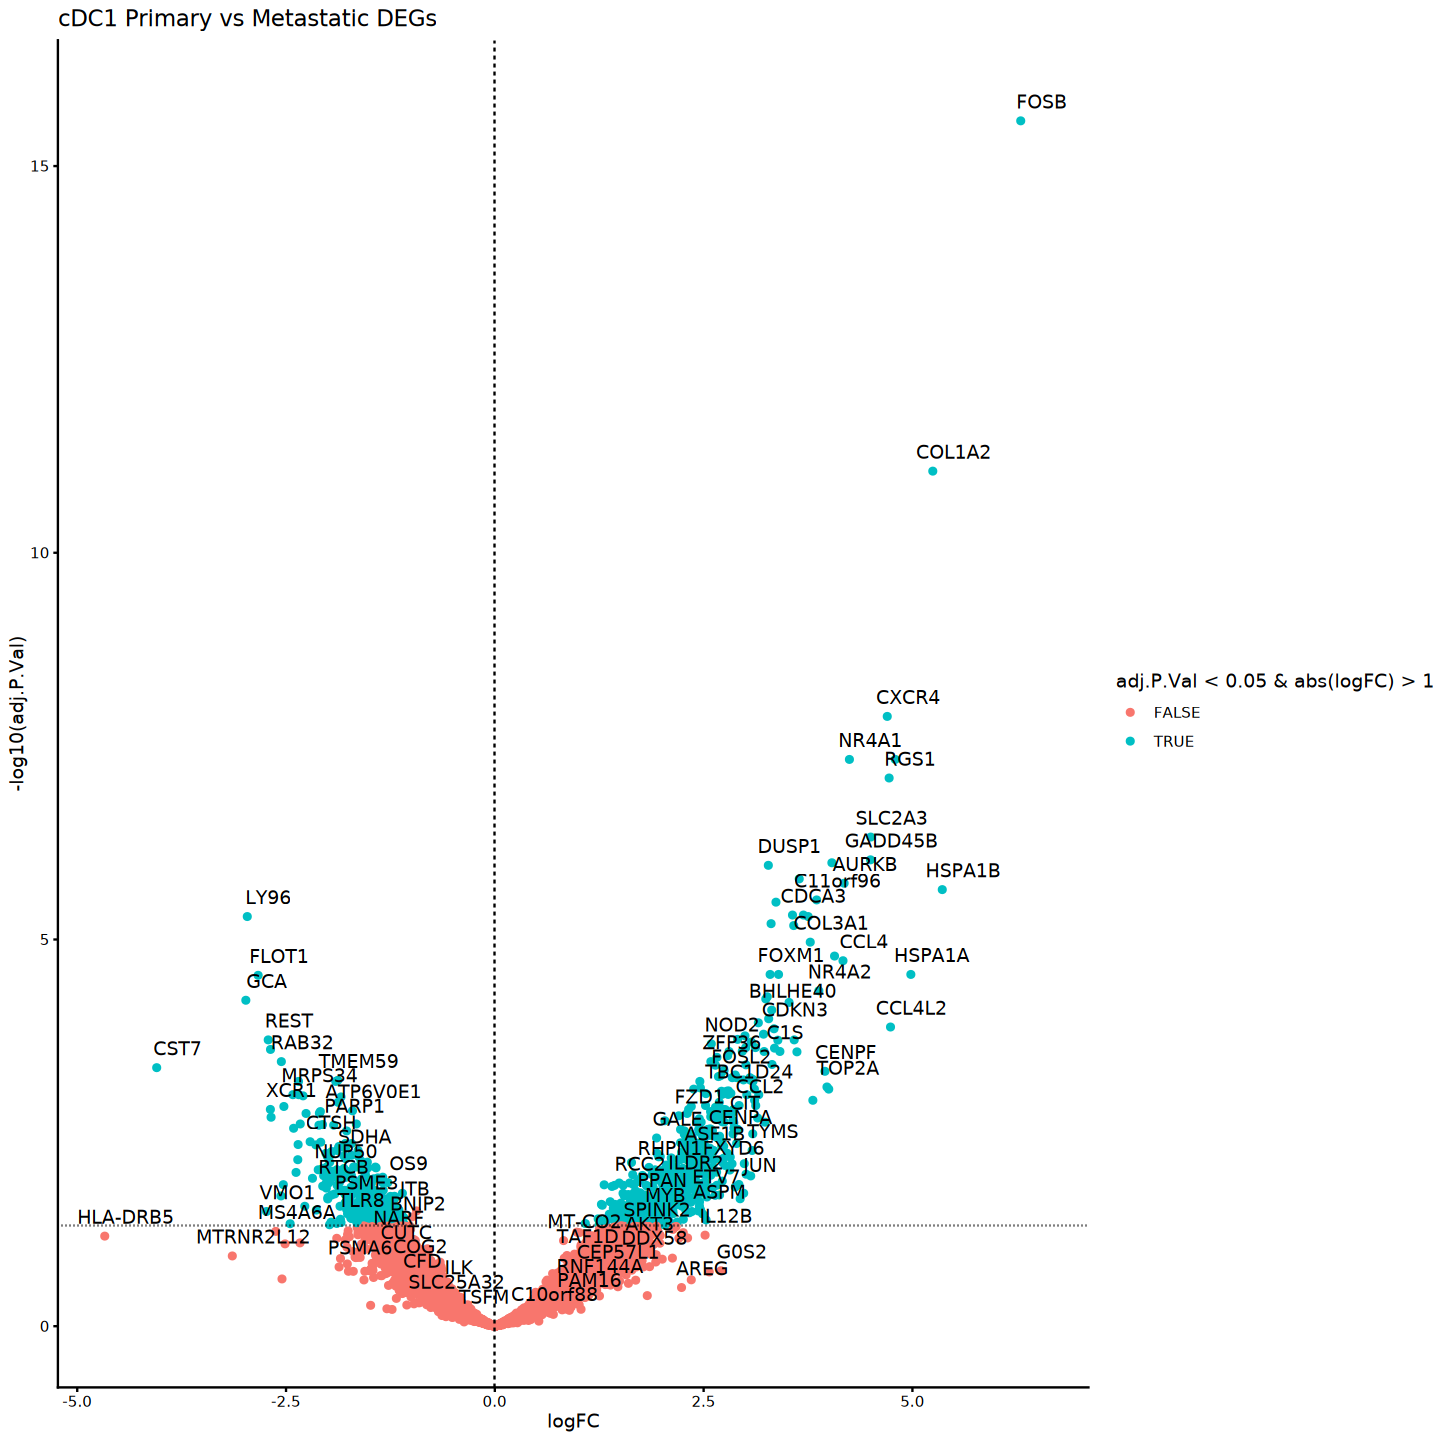

In [150]:
tt1_dc1$gene <- rownames(tt1_dc1)

ggplot(tt1_dc1,
       aes(logFC, -log10(adj.P.Val), label = gene)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(tt1_dc1$gene), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "cDC1 Primary vs Metastatic DEGs")

In [ ]:
# export to csv
#write.csv(dc1_up_genes, "MTvPT_DEG_results/dc1_up_genes.csv", quote = FALSE, row.names = FALSE)
#write.csv(dc1_down_genes, "MTvPT_DEG_results/dc1_down_genes.csv", quote = FALSE, row.names = FALSE)

## Load data - DC2

In [122]:
#load data
sampleinfo <- read.csv("oc_pseudobulk_sampletype_metadata_DC2.csv", row.names =1)
head(sampleinfo)

,sample_type_major2
,<chr>
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,metastatic tumour


In [124]:
dim(sampleinfo)

[1] 175   1

In [125]:
cts_DC2 <- read.csv("oc_pseudobulk_DC2_data.csv")
head(cts_DC2)

,X,GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL,⋯,PRJCA005422_HGSOC6_AS,PRJCA005422_HGSOC6_MT,PRJCA005422_HGSOC6_PT,PRJCA005422_HGSOC7_PT,PRJCA005422_HGSOC8_AS,PRJCA005422_HGSOC8_PT,PRJCA005422_HGSOC9_AS,PRJCA005422_HGSOC9_PT,PRJCA005422_HGSOC10_AS,PRJCA005422_HGSOC10_PT
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FAM87B,0,0,0,0,0,0,0,0,0,⋯,0,1,0,0,0,0,0,0,0,0
2,LINC00115,0,1,0,0,1,0,0,1,0,⋯,6,1,0,1,0,0,0,0,0,0
3,FAM41C,0,1,0,0,0,0,0,0,0,⋯,1,0,0,1,0,0,0,0,0,1
4,SAMD11,0,0,0,0,0,0,0,0,0,⋯,0,0,0,1,0,0,0,0,0,0
5,NOC2L,2,7,3,0,3,0,1,1,0,⋯,20,3,3,7,1,0,3,2,8,3
6,KLHL17,0,0,0,0,0,1,0,0,0,⋯,0,0,0,0,0,0,0,1,1,0


In [127]:
dim(cts_DC2)

[1] 15074   176

In [128]:
# set genes variables
genes <- data.frame(Symbol = row.names(cts_DC2))

In [129]:
# create DGEList variable
y <- DGEList(counts = cts_DC2, genes = genes)

Setting first column of `counts` as gene annotation.



### Filtering:

In [130]:
# Keep genes with total counts more than 50.
A <- rowSums(y$counts)
isexpr <- A > 50

In [131]:
# Keep only genes with defined annotation:
hasannot <- rowSums(is.na(y$genes)) == 0

In [132]:
y <- y[isexpr & hasannot, , keep.lib.size = FALSE]
dim(y)

[1] 11209   175

### Normalise data

In [133]:
y <- calcNormFactors(y)
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     0
3                                                     0
5                                                     2
6                                                     0
8                                                     0
9                                                    22
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
2                                              1
3                                              1
5                                              7
6                                              0
8                                              1
9                                             31
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
2                                                        0
3                                                        0
5                                                        3
6                                                        0
8                                                        3
9                                                       49
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
2                                                 0
3                                                 0
5                                                 0
6                                                 0
8                                                 1
9                                                28
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
2                                                         1
3                                                         0
5                                                         3
6                                                         0
8                                                         0
9                                                        25
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
2                                                       0
3                                                       0
5                                                       0
6                                                       1
8                                                       5
9                                                      42
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
2                                                  0
3                                                  0
5                                                  1
6                                                  0
8                                                  1
9                                                 21
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
2                                                          1
3                                                          0
5                                                          1
6                                                          0
8                                                          2
9                                                          9
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
2                                        0
3                                        0
5                                        0
6                                        0
8                                        0
9                                        6
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     2
3                                                     3
5                                                    13
6                                                     0
8                                                     4
9                                                    51
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
2                                        2
3                                        0
5    

## Set up Model

In [134]:
# setup model
design <- model.matrix(~ 0 + sample_type_major2, data = sampleinfo)

In [136]:
colnames(design) <- c("primary tumour","metastatic tumour","ascites","healthy")

In [137]:
head(design)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


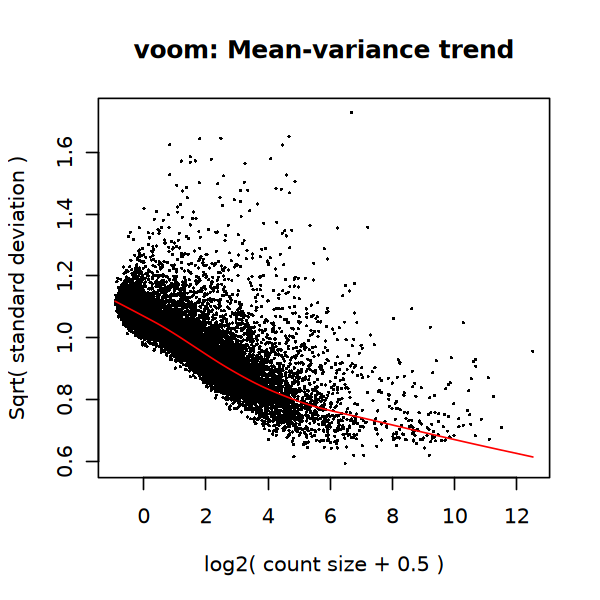

In [138]:
#Voom plot
options(repr.plot.height=5, repr.plot.width=5)
v <- voom(y, design, plot = TRUE)

In [139]:
# lmFit
fit <- lmFit(v, design)

In [140]:
#duplicate data
design2 <- design
head(design2)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


### Primary vs Metastatic set as design 1 and 2

In [141]:
# Rename columns to remove the spaces
colnames(design2)[1] <- "primary_tumour"
colnames(design2)[2] <- "metastatic_tumour"

## Flip primary and metastatic comparison

In [142]:
# make contrast matrix, apply contrasts, and fit the model 
#contrast.matrix <- makeContrasts(primary_tumour - metastatic_tumour, levels = design2) #compare primary to metastatic
contrast.matrix <- makeContrasts(metastatic_tumour - primary_tumour, levels = design2) #compare primary to metastatic
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [143]:
# check the results
tt1_dc2 <- topTable(fit2, coef=1, adjust="BH", number = Inf) #primary_tumour-metastatic_tumour

In [144]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)

       metastatic_tumour - primary_tumour
Down                                  120
NotSig                              10570
Up                                    519

In [145]:
head(tt1_dc2)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
14192,FOSB,14192,7.172775,8.061751,16.44486,3.454625e-38,3.872290e-34,75.59583
2181,NR4A2,2181,6.283017,8.034056,14.33984,5.913278e-32,3.314096e-28,61.62468
9530,NR4A1,9530,5.817679,7.428508,11.95837,7.459203e-25,2.787007e-21,45.67630
1262,PTGS2,1262,6.713193,5.891439,11.64059,6.504013e-24,1.822587e-20,43.48866
1401,ATF3,1401,5.565390,7.097458,11.37864,3.851633e-23,8.634590e-20,41.82205
10247,GPR183,10247,4.562681,9.016367,11.16021,1.688578e-22,3.154545e-19,40.46262


In [147]:
# 1. Assign the column values to row names
rownames(tt1_dc2) <- tt1_dc2$X

In [148]:
# select top 250 up, and 250 down genes from tt1
dc2_up_genes<- tt1_dc2 %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character
dc2_down_genes <- tt1_dc2 %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character

In [152]:
plot_genes_tt1 <- c(dc2_up_genes, dc2_down_genes)

In [154]:
head(dc2_up_genes)

[1] "FOSB"   "NR4A2"  "NR4A1"  "PTGS2"  "ATF3"   "GPR183"

In [155]:
head(dc2_down_genes)

[1] "APPL1" "HCK"   "PRMT2" "DSC2"  "MTIF2" "TSR2"

## Save data

In [156]:
dim(tt1_dc2)

[1] 11209     8

In [ ]:
# export as csv
#write.csv(tt1_dc2, "MTvPT_DEG_results/MT-PT_limma_dc2.csv", quote = FALSE, row.names = FALSE)

## Volcano Plots

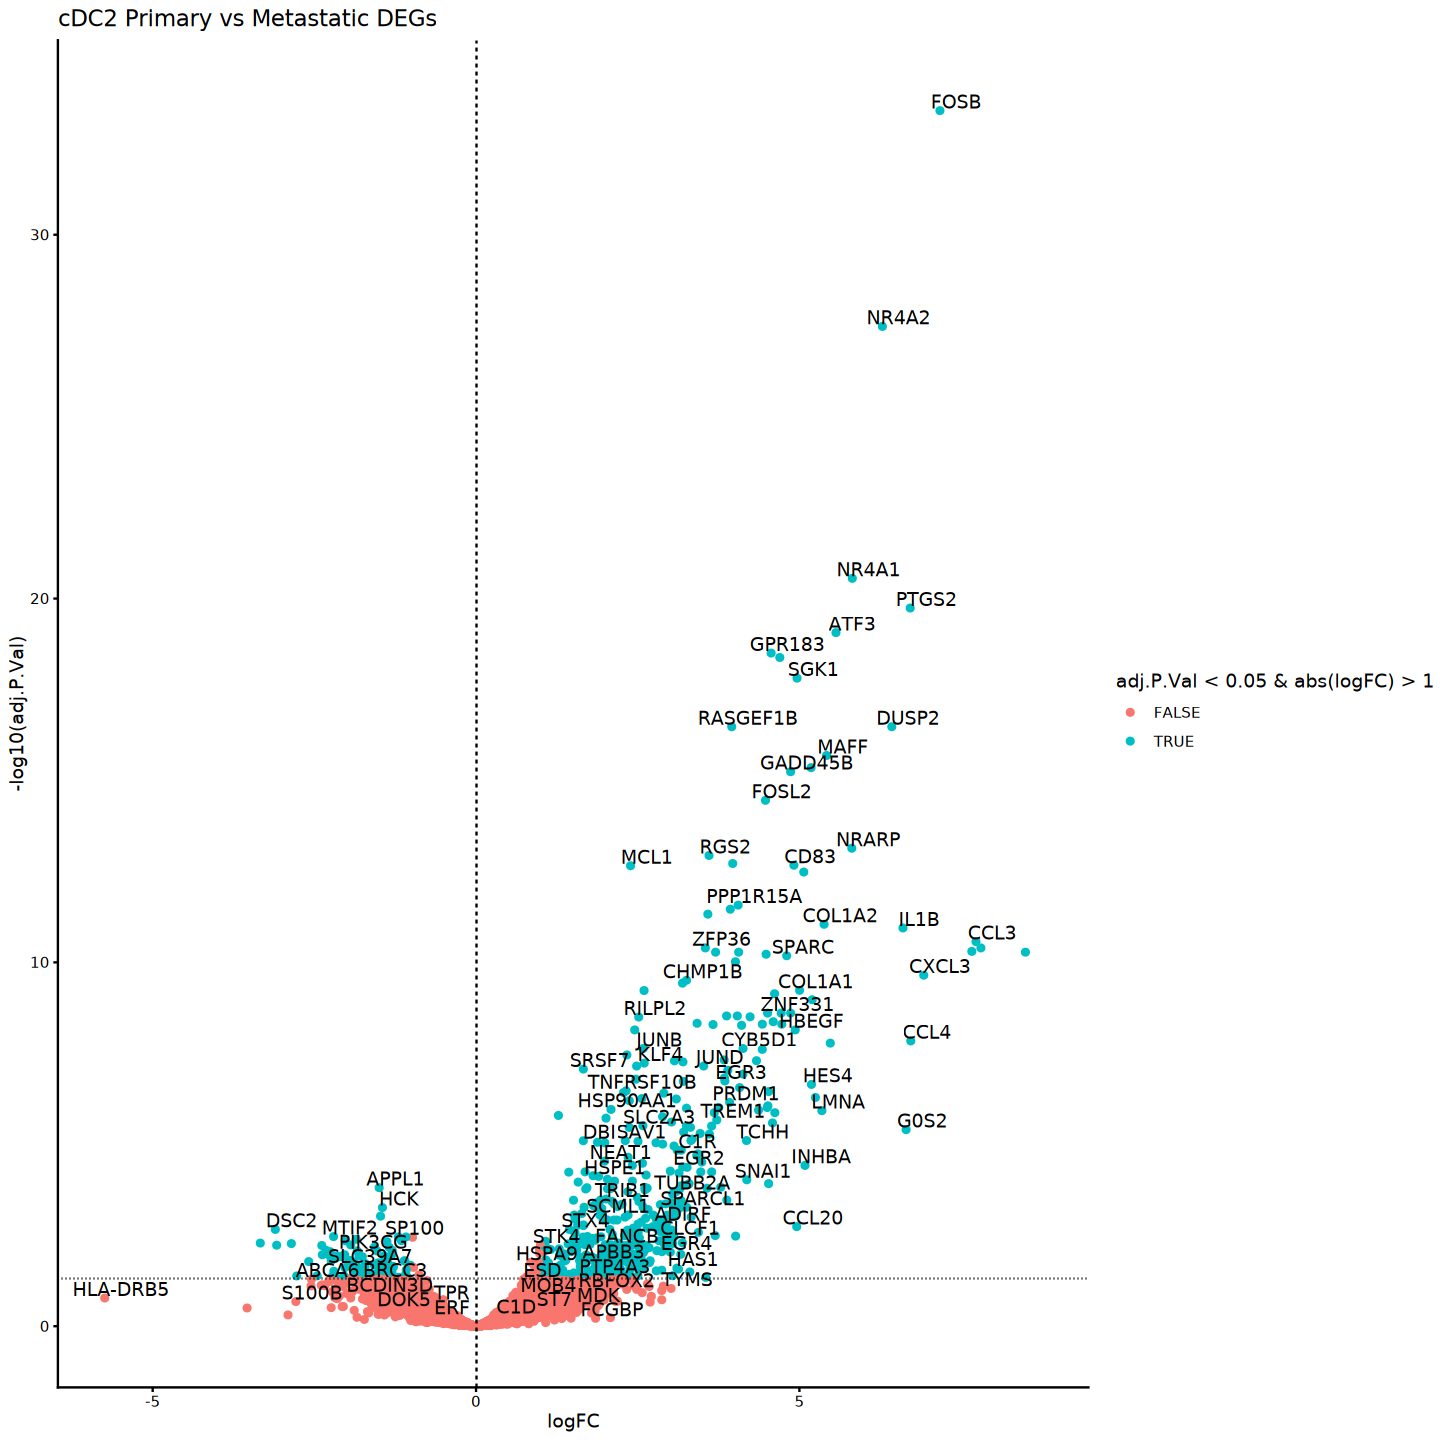

In [158]:
tt1_dc2$gene <- rownames(tt1_dc2)

ggplot(tt1_dc2,
       aes(logFC, -log10(adj.P.Val), label = gene)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(tt1_dc2$gene), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "cDC2 Primary vs Metastatic DEGs")

## Load data - mregDC

In [4]:
#load data
sampleinfo <- read.csv("oc_pseudobulk_sampletype_metadata_mregDC.csv", row.names =1)
head(sampleinfo)

,sample_type_major2
,<chr>
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,primary tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,metastatic tumour


In [5]:
dim(sampleinfo)

[1] 167   1

In [6]:
cts_mregDC <- read.csv("oc_pseudobulk_mregDC_data.csv")
head(cts_mregDC)

,X,GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL,⋯,PRJCA005422_HGSOC6_AS,PRJCA005422_HGSOC6_MT,PRJCA005422_HGSOC6_PT,PRJCA005422_HGSOC7_PT,PRJCA005422_HGSOC8_AS,PRJCA005422_HGSOC8_PT,PRJCA005422_HGSOC9_AS,PRJCA005422_HGSOC9_PT,PRJCA005422_HGSOC10_AS,PRJCA005422_HGSOC10_PT
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,FAM87B,0,0,0,0,0,0,0,0,0,⋯,0,1,0,0,0,0,0,0,0,0
2,LINC00115,0,0,0,0,0,0,0,1,0,⋯,1,1,0,1,0,0,1,0,0,0
3,FAM41C,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
4,SAMD11,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
5,NOC2L,0,0,1,0,0,1,0,1,2,⋯,0,2,0,1,0,0,3,0,0,0
6,KLHL17,0,0,1,0,0,1,0,0,0,⋯,0,1,0,0,0,0,1,0,1,0


In [7]:
dim(cts_mregDC)

[1] 15074   168

In [8]:
# set genes variables
genes <- data.frame(Symbol = row.names(cts_mregDC))

In [9]:
# create DGEList variable
y <- DGEList(counts = cts_mregDC, genes = genes)

Setting first column of `counts` as gene annotation.



### Filtering:

In [10]:
# Keep genes with total counts more than 50.
A <- rowSums(y$counts)
isexpr <- A > 50

In [11]:
# Keep only genes with defined annotation:
hasannot <- rowSums(is.na(y$genes)) == 0

In [12]:
y <- y[isexpr & hasannot, , keep.lib.size = FALSE]
dim(y)

[1] 8553  167

### Normalise data

In [13]:
y <- calcNormFactors(y)
head(y)

An object of class "DGEList"
$counts
   GSE180661_SPECTRUM.OV.002_S1_CD45P_INFRACOLIC_OMENTUM
5                                                      0
8                                                      0
9                                                      0
10                                                     0
12                                                     0
14                                                     0
   GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
5                                               0
8                                               1
9                                               4
10                                              0
12                                              0
14                                              1
   GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
5                                                         1
8                                                         1
9                                                         4
10                                                        0
12                                                        0
14                                                        1
   GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
5                                                  0
8                                                  2
9                                                  2
10                                                 0
12                                                 0
14                                                 1
   GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
5                                                          0
8                                                          2
9                                                          3
10                                                         1
12                                                         0
14                                                         2
   GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
5                                                        1
8                                                        1
9                                                       25
10                                                       0
12                                                       1
14                                                       0
   GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
5                                                   0
8                                                   0
9                                                   1
10                                                  0
12                                                  0
14                                                  0
   GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
5                                                           1
8                                                           0
9                                                           1
10                                                          0
12                                                          1
14                                                          0
   GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
5                                         2
8                                         0
9                                        24
10                                        4
12                                        0
14                                        0
   GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
5                                                      1
8                                                      0
9                                                      3
10                                                     2
12                                                     0
14                                                     1
   GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
5                   

## Set up Model

In [14]:
# setup model
design <- model.matrix(~ 0 + sample_type_major2, data = sampleinfo)

In [15]:
colnames(design) <- c("primary tumour","metastatic tumour","ascites","healthy")

In [16]:
head(design)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


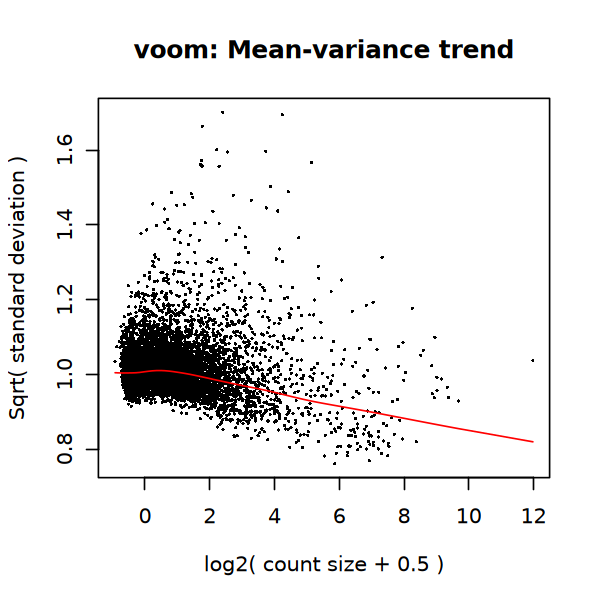

In [17]:
#Voom plot
options(repr.plot.height=5, repr.plot.width=5)
v <- voom(y, design, plot = TRUE)

In [21]:
# lmFit
fit <- lmFit(v, design)

In [18]:
#duplicate data
design2 <- design
head(design2)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0


### Primary vs Metastatic set as design 1 and 2

In [19]:
# Rename columns to remove the spaces
colnames(design2)[1] <- "primary_tumour"
colnames(design2)[2] <- "metastatic_tumour"

## Flip primary and metastatic comparison

In [22]:
# make contrast matrix, apply contrasts, and fit the model 
#contrast.matrix <- makeContrasts(primary_tumour - metastatic_tumour, levels = design2) #compare primary to metastatic
contrast.matrix <- makeContrasts(metastatic_tumour - primary_tumour, levels = design2) #compare primary to metastatic
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [23]:
# check the results
tt1_mregdc <- topTable(fit2, coef=1, adjust="BH", number = Inf) #primary_tumour-metastatic_tumour

In [24]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)

       metastatic_tumour - primary_tumour
Down                                    9
NotSig                               8543
Up                                      1

In [25]:
head(tt1_mregdc)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
13983,TYROBP,13983,-5.569684,10.029229,-4.889259,2.067751e-06,0.01768548,4.389553
11428,RPS15A,11428,-4.338221,10.945403,-4.648081,6.057856e-06,0.02590642,3.476500
6190,SLC25A6,6190,-4.443334,8.739950,-4.419996,1.613761e-05,0.03369127,2.630757
3890,RPS3A,3890,-4.188353,11.250495,-4.293620,2.733791e-05,0.03369127,2.201090
8499,ZC3H12C,8499,4.432971,3.956478,4.274173,2.961797e-05,0.03369127,2.127371
477,RPS8,477,-3.588908,11.325386,-4.221489,3.674576e-05,0.03369127,1.969344


In [26]:
# 1. Assign the column values to row names
rownames(tt1_mregdc) <- tt1_mregdc$X

In [27]:
# select top 250 up, and 250 down genes from tt1
mregdc_up_genes<- tt1_mregdc %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character
mregdc_down_genes <- tt1_mregdc %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character

In [28]:
plot_genes_tt1 <- c(mregdc_up_genes, mregdc_down_genes)

## Save data

In [29]:
dim(tt1_mregdc)

[1] 8553    8

In [30]:
# export as csv
write.csv(tt1_mregdc, "MTvPT_DEG_results/MT-PT_limma_mregdc.csv", quote = FALSE, row.names = FALSE)

## Volcano Plots

In [31]:
options(repr.plot.width=12, repr.plot.height=12)

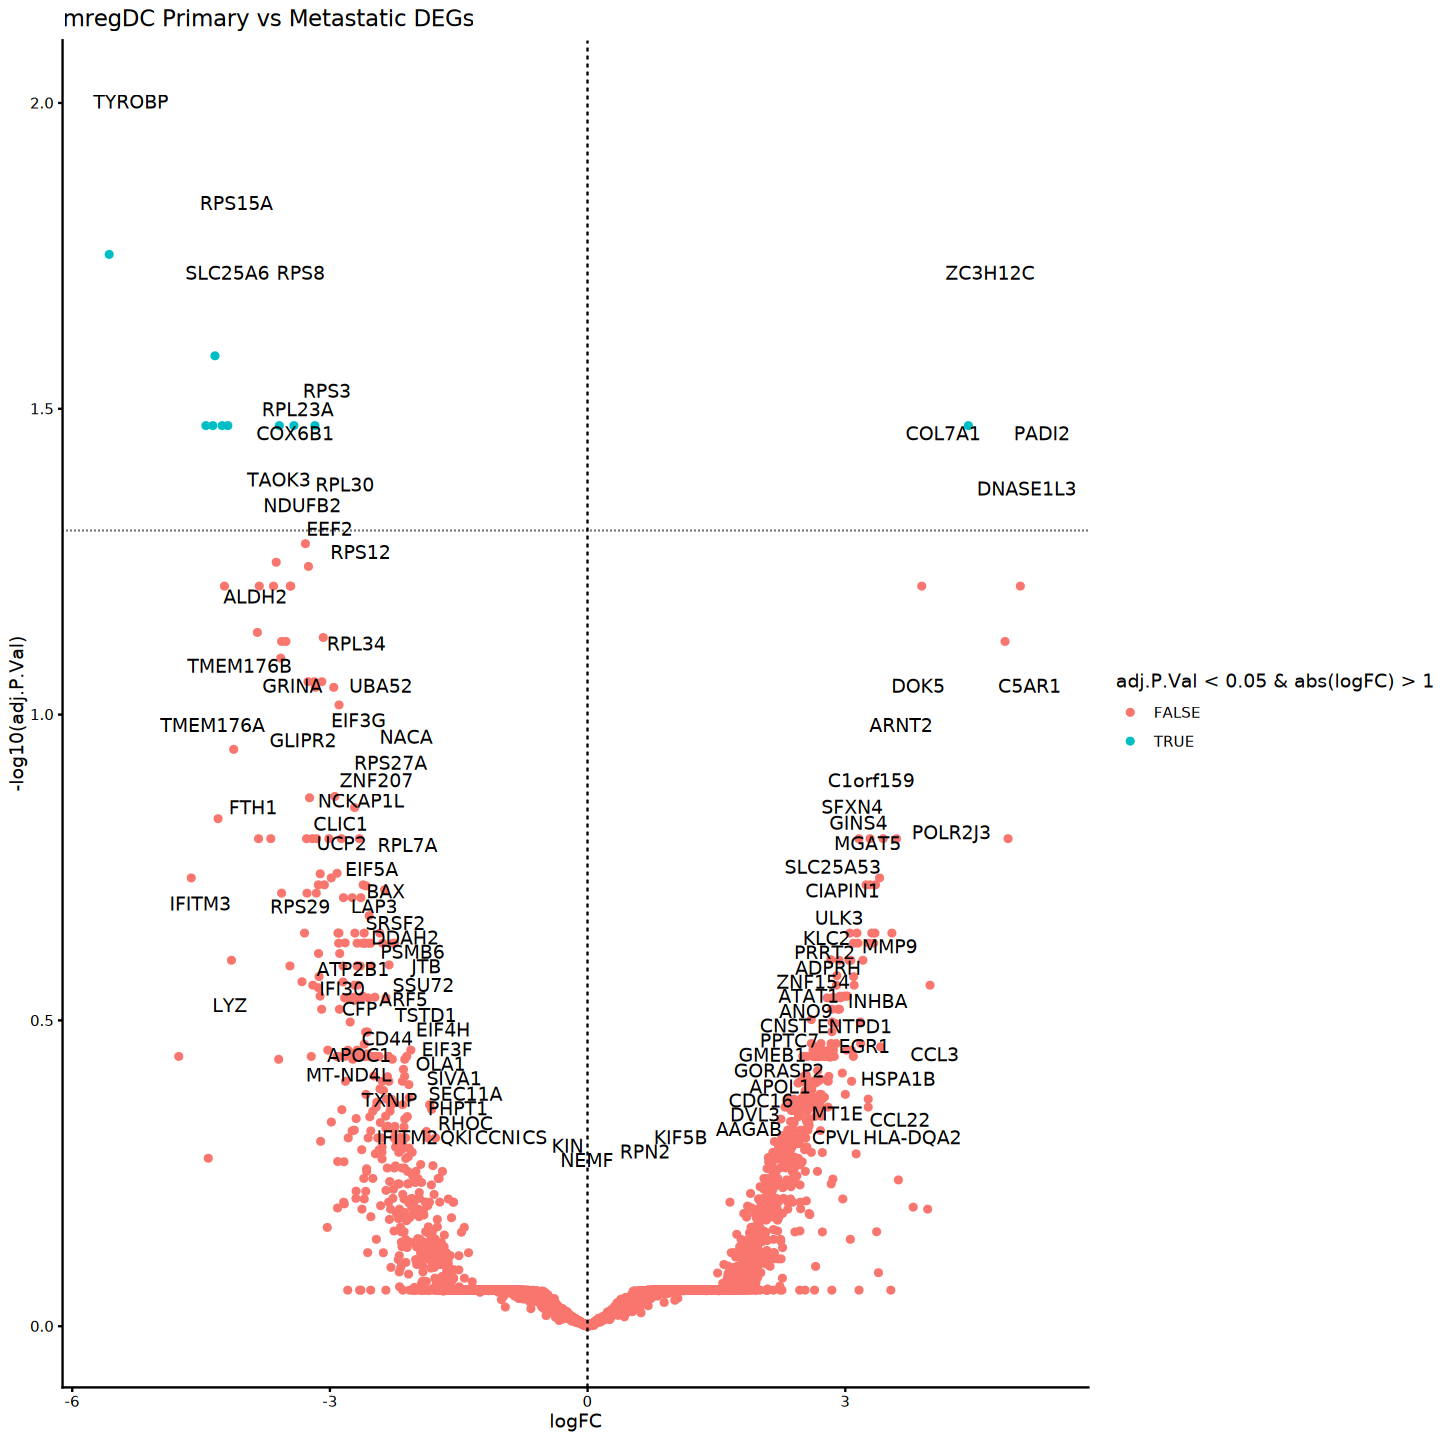

In [32]:
tt1_mregdc$gene <- rownames(tt1_mregdc)

ggplot(tt1_mregdc,
       aes(logFC, -log10(adj.P.Val), label = gene)) +
       geom_point(aes(
        color =
        adj.P.Val < 0.05 &
        abs(logFC) > 1
    )) +
    geom_vline(xintercept = c(0), linetype = "dashed", color = "black") +
    geom_hline(yintercept = c(-log10(0.05)), linetype = "dotted", color = "black") +
    geom_text(
    label = rownames(tt1_mregdc$gene), 
    nudge_x = 0.25, nudge_y = 0.25, 
    check_overlap = T) +
    theme_classic() +
    labs(title = "mregDC Primary vs Metastatic DEGs")

Edit abs logFC threshold